# Supergranulation with the dopplergrams of Haywood et al. (2016): one good and one bad day

In [1]:
import os, json, glob, shutil, tempfile, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from argparse import Namespace
from IPython.display import Image, display
from sunsim import local_path, sdo, supergranulation as sg

DAYS = {'2021-05-25': 'good: old r = 0.90', '2021-05-15': 'bad: old r = 0.13'}   # RV, per_day_table of the quality run
OUT = str(local_path('supergranulation_haywood_results'))   # days/ and results/ of PIC/supergranulation_haywood.py
OLD = str(local_path('supergranulation_results'))           # the earlier run (PIC/supergranulation.py)
OLD_RESULTS = 'results_quality_0.99_days50'
RESULTS = 'results_2days_quality_0.99'
START = '2021-05-01'
N_RINGS = 30
WINDOW = 720.0                                              # [s] 45 s dopplergrams averaged around every exposure
MU_MIN = 0.1
MIN_OBS_QUALITY = 0.99
MIN_DAY_EXP = 50
THRESHOLDS = dict(noise_th=8.0, B_th=24.0, I_th=0.89, A_th=20.0, mu_area=0.1, faculae='plage')
HARPSN = str(local_path('harpsn_sun'))
RUN_DAYS = False                                            # True: the day step here (~14 GB from JSOC per day)

spec = importlib.util.spec_from_file_location('sgh', os.path.join('..', 'PIC', 'supergranulation_haywood.py'))
sgh = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sgh)
COL = {'harpsn': '#102e37', 'maps': '#ea8642', 'new': '#45a5aa', 'old': '#d1495b', 'old_pm': '#c4a000'}

In [13]:
%matplotlib inline

## 1. Day step

In [2]:
for day in DAYS:
    done_file = os.path.join(OUT, 'days', day, 'done.json')
    if RUN_DAYS and not os.path.exists(done_file):
        sgh.run_day(Namespace(date=day, out=OUT, harpsn=HARPSN, quality=False, size=4096, n_rings=N_RINGS,
                              network_velocity=True, max_dt=900.0, window=WINDOW, mu_min=MU_MIN, workers=2, tmp=None,
                              limit=0, dry_run=False, **THRESHOLDS))
    print(day, DAYS[day], json.load(open(done_file)) if os.path.exists(done_file) else 'not done')

2021-05-25 good: old r = 0.90 {'date': '2021-05-25', 'n_exp': 71, 'n_epochs': 33, 'epochs_done': 33, 'n_frames': 523, 'frames_done': 523, 'failed': 0, 'window': 720.0, 'mu_min': 0.1, 'network_velocity': True, 'n_rings': 30, 'size': 4096, 'thresholds': {'noise_th': 8.0, 'B_th': 24.0, 'I_th': 0.89, 'A_th': 20.0, 'mu_area': 0.1, 'faculae': 'plage'}}
2021-05-15 bad: old r = 0.13 {'date': '2021-05-15', 'n_exp': 71, 'n_epochs': 33, 'epochs_done': 33, 'n_frames': 545, 'frames_done': 545, 'failed': 0, 'window': 720.0, 'mu_min': 0.1, 'network_velocity': True, 'n_rings': 30, 'size': 4096, 'thresholds': {'noise_th': 8.0, 'B_th': 24.0, 'I_th': 0.89, 'A_th': 20.0, 'mu_area': 0.1, 'faculae': 'plage'}}


## 2. One dopplergram of each day

In [3]:
def block_mean(a, step):
    """Mean of every block of step x step pixels (NaN ignored)."""
    n = a.shape[0] // step * step
    with np.errstate(invalid='ignore'):
        return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))


def one_frame(day, hour=12.0, step=8):
    """The epoch and the 45 s dopplergram closest to day + hour (UTC): corrections, identification and projection;
    the FITS are deleted. Returns images of step x step blocks in the frame of the maps (origin='lower')."""
    from sunsim import observations as obs
    jd = obs.jd_of_date(day) + hour / 24
    ci = sg.query_records(sg.SERIES['continuum'][0], jd - 600 / 86400, jd + 600 / 86400)
    ci = ci.iloc[[sg.closest(jd, ci['jd'].values)[0][0]]]
    ma = sg.query_records(sg.SERIES['magnetogram'][0], ci['jd'].values[0] - 60 / 86400, ci['jd'].values[0] + 60 / 86400)
    r45 = sg.query_records(sg.SERIES_45S[0], jd - 60 / 86400, jd + 60 / 86400)
    folder = tempfile.mkdtemp(prefix='hmi_')
    try:
        files = sg.fetch_epoch({'continuum': ci['T_REC'].values[0],
                                'magnetogram': ma['T_REC'].values[sg.closest(ci['jd'].values[0], ma['jd'].values)[0][0]]}, folder)
        f45 = sg.fetch_record(sg.SERIES_45S[0], r45['T_REC'].values[sg.closest(jd, r45['jd'].values)[0][0]],
                              sg.SERIES_45S[1], folder)
        ident = sg.identify_epoch(files, size=4096, n_rings=N_RINGS, thresholds=THRESHOLDS)
        ctx = ident['context']
        dop = sg.read_record(*f45)
        c = sg.correct_dopplergram(dop, components=True)
        lo, hi = ctx['lo'], ctx['hi']
        cut = lambda a: block_mean(np.flip(np.asarray(a, dtype=np.float32)[lo:hi, lo:hi]), step)
        out = {'raw': cut(dop.data), 'v_sc': cut(c['v_sc']), 'v_rot': cut(c['v_rot']), 'v': cut(c['v']),
               'mu': cut(c['mu']), 'quiet': block_mean(ctx['quiet'].astype(np.float32), step) > 0.5, 't_obs': f45[1]['T_OBS'],
               'keys': {k: c[k] for k in ('obs_vr', 'obs_vw', 'obs_vn', 'B0')}}
        fr = sg.frame_cell_sums(f45, ctx, n_rings=N_RINGS, mu_min=MU_MIN)
        out.update(v_cell=sg.cell_velocities(fr['swv'], fr['sw']), sw=fr['sw'], shift_px=fr['shift_px'],
                   ff_sp_disc=ident['ff_sp_disc'], ff_fc_disc=ident['ff_fc_disc'])
        del dop, c, ident, ctx
    finally:
        shutil.rmtree(folder, ignore_errors=True)
    return out

one = {day: one_frame(day) for day in DAYS}
for day, o in one.items():
    print('%s %s: T_OBS %s, OBS_VR %.0f, OBS_VW %.0f, OBS_VN %.0f m/s, B0 %.2f deg, shift %.2f px, spots %.3f %%, '
          'faculae %.2f %%' % (day, DAYS[day], o['t_obs'], o['keys']['obs_vr'], o['keys']['obs_vw'], o['keys']['obs_vn'],
                               o['keys']['B0'], o['shift_px'], o['ff_sp_disc'], o['ff_fc_disc']))

/Users/sophiestucki/miniforge3/envs/sunsim/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_49759/1215535224.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_49759/1215535224.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))


2021-05-25 good: old r = 0.90: T_OBS 2021.05.25_12:00:51_TAI, OBS_VR -1701, OBS_VW 30187, OBS_VN 1555 m/s, B0 -1.44 deg, shift 0.21 px, spots 0.043 %, faculae 1.44 %
2021-05-15 bad: old r = 0.13: T_OBS 2021.05.15_12:00:51_TAI, OBS_VR -1637, OBS_VW 30434, OBS_VN 1462 m/s, B0 -2.61 deg, shift 0.23 px, spots 0.016 %, faculae 1.25 %


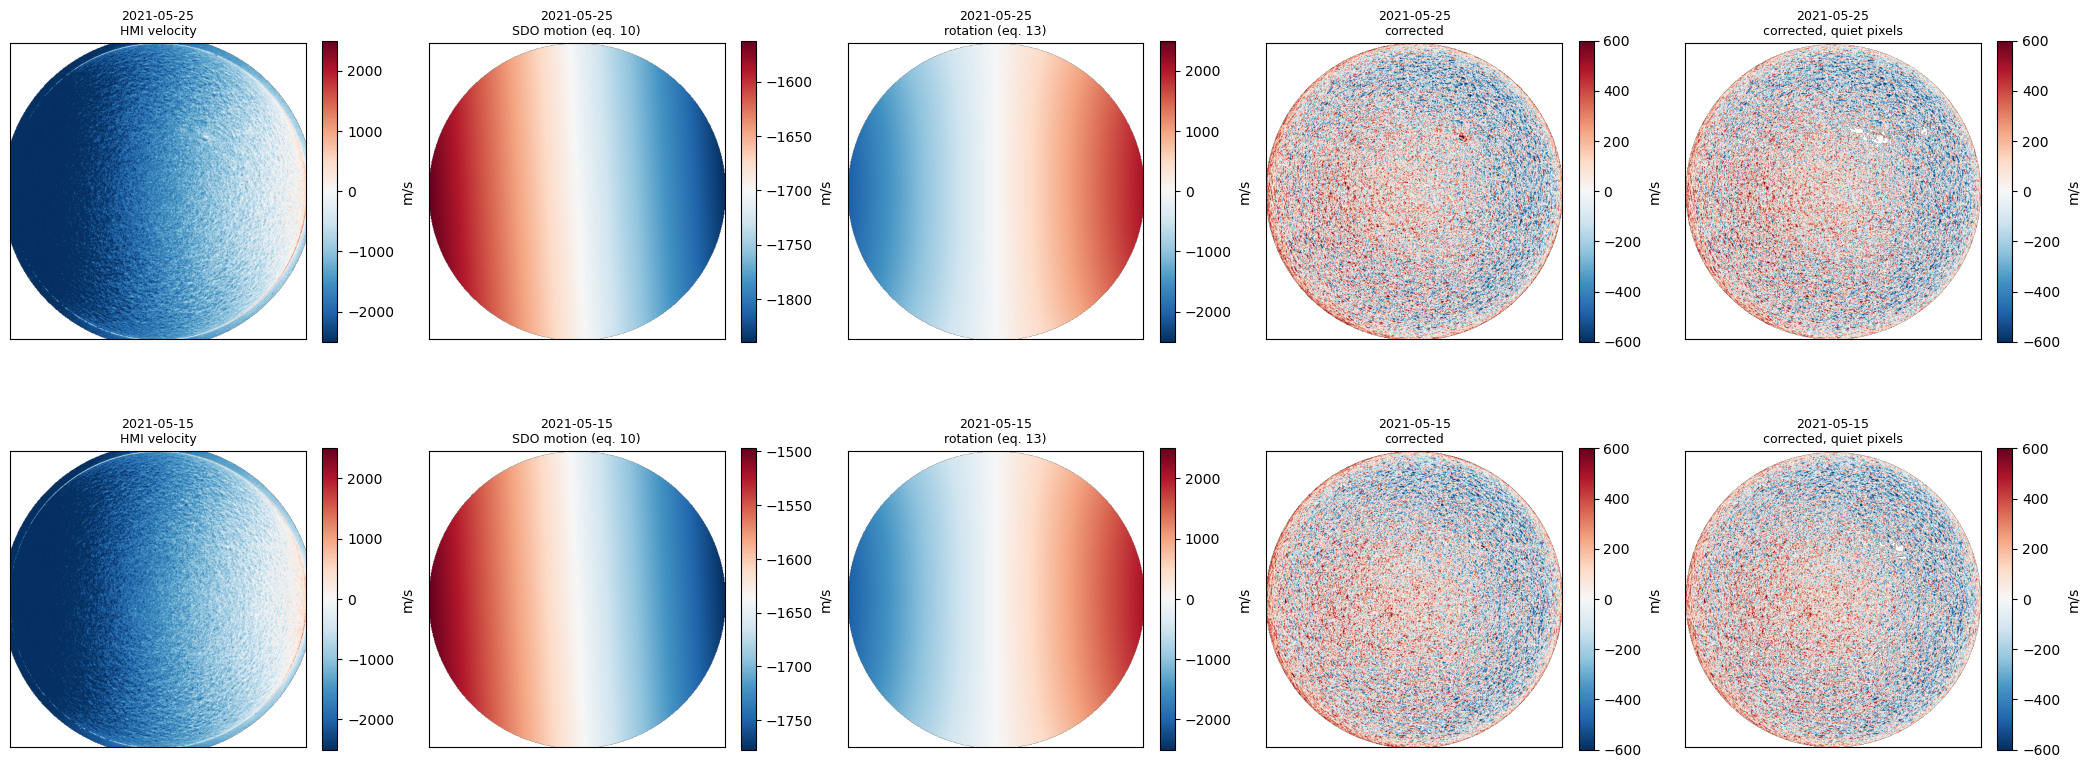

In [4]:
panels = (('raw', 'HMI velocity', 2500), ('v_sc', 'SDO motion (eq. 10)', None), ('v_rot', 'rotation (eq. 13)', 2500),
          ('v', 'corrected', 600), ('v_quiet', 'corrected, quiet pixels', 600))
fig, axes = plt.subplots(len(one), len(panels), figsize=(4.2 * len(panels), 4.2 * len(one)), squeeze=False)
for row, (day, o) in zip(axes, one.items()):
    o['v_quiet'] = np.where(o['quiet'] & (o['mu'] > MU_MIN), o['v'], np.nan)
    for ax, (key, title, lim) in zip(row, panels):
        a = o[key]
        if lim is None:
            im = ax.imshow(a, origin='lower', cmap='RdBu_r', vmin=np.nanmin(a), vmax=np.nanmax(a))
        else:
            im = ax.imshow(a, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim)
        ax.set_title('%s\n%s' % (day, title), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, label='m/s')
plt.tight_layout()

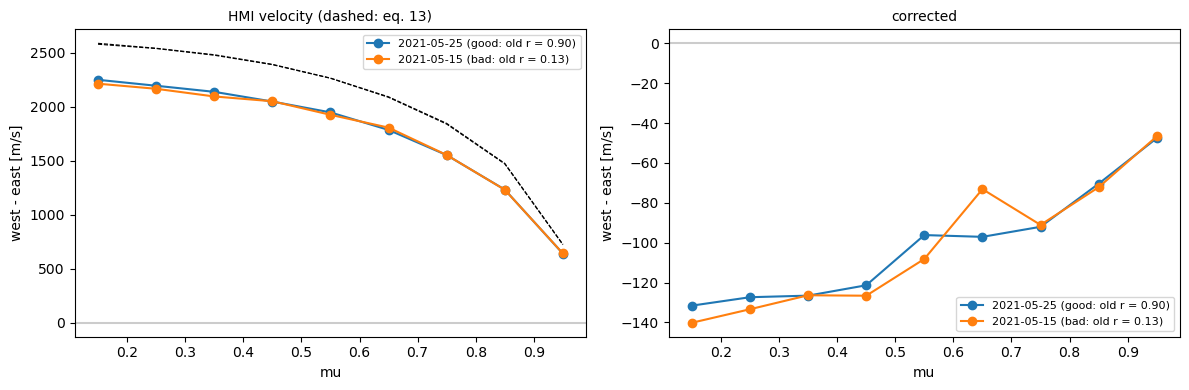

In [5]:
def west_east(a, mu, bins=np.linspace(0.1, 1, 10)):
    """Median of a in the west half minus in the east half, in bins of mu (frame of the maps: west on the right)."""
    x = np.arange(a.shape[1])[None, :] - (a.shape[1] - 1) / 2 + np.zeros(a.shape)
    out = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        k = np.isfinite(a) & (mu >= lo) & (mu < hi)
        out.append(np.nanmedian(a[k & (x > 0)]) - np.nanmedian(a[k & (x < 0)]))
    return (bins[:-1] + bins[1:]) / 2, np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for day, o in one.items():
    for ax, key in zip(axes, ('raw', 'v')):
        mu_c, d = west_east(o[key], o['mu'])
        ax.plot(mu_c, d, 'o-', label='%s (%s)' % (day, DAYS[day]))
    mu_c, d = west_east(o['v_rot'], o['mu'])
    axes[0].plot(mu_c, d, 'k--', lw=0.8)
for ax, t in zip(axes, ('HMI velocity (dashed: eq. 13)', 'corrected')):
    ax.axhline(0, color='k', alpha=0.2)
    ax.set_xlabel('mu'); ax.set_ylabel('west - east [m/s]'); ax.set_title(t, fontsize=10); ax.legend(fontsize=8)
plt.tight_layout()

## 3. Velocities of the cells of every exposure

In [6]:
ex, ep, frames, windows = sgh.load_days(OUT, N_RINGS)
keep = np.isin(ex['day'], list(DAYS))
ex = {k: v[keep] for k, v in ex.items()}
v_exp = np.full((len(ex['jd']), ep['ff_sp'].shape[1]), np.nan)
sw_exp = np.zeros_like(v_exp)
n45, ok45 = np.zeros(len(ex['jd']), int), np.zeros(len(ex['jd']), bool)
for d in DAYS:
    m = np.flatnonzero(ex['day'] == d)
    jd45, swv, sw, info = frames[d]
    v_exp[m], sw_exp[m], n45[m], ok45[m] = sg.window_average(jd45, swv, sw, ex['jd'][m], window=WINDOW)
v_fill, filled = sg.fill_empty_cells(v_exp, sw_exp, N_RINGS)
fr = pd.concat([pd.DataFrame(frames[d][3]).assign(day=d) for d in DAYS], ignore_index=True)
print('exposures: %s; frames per exposure %d to %d; with >= 80 %% of the frames: %d of %d; empty cells per exposure %.1f'
      % (dict(zip(*np.unique(ex['day'], return_counts=True))), n45.min(), n45.max(), ok45.sum(), len(ok45),
         filled.sum(axis=1).mean()))

exposures: {np.str_('2021-05-15'): np.int64(71), np.str_('2021-05-25'): np.int64(71)}; frames per exposure 8 to 16; with >= 80 % of the frames: 139 of 142; empty cells per exposure 134.3


/Users/sophiestucki/sunsim/sunsim/sdo.py:402: UserWarning: 2 cells of the grid of 30 rings have no pixel in 512 x 512 maps (taken as quiet): use larger maps or fewer rings (max_rings)
  warnings.warn('%d cells of the grid of %d rings have no pixel in %d x %d maps (taken as quiet): use larger '


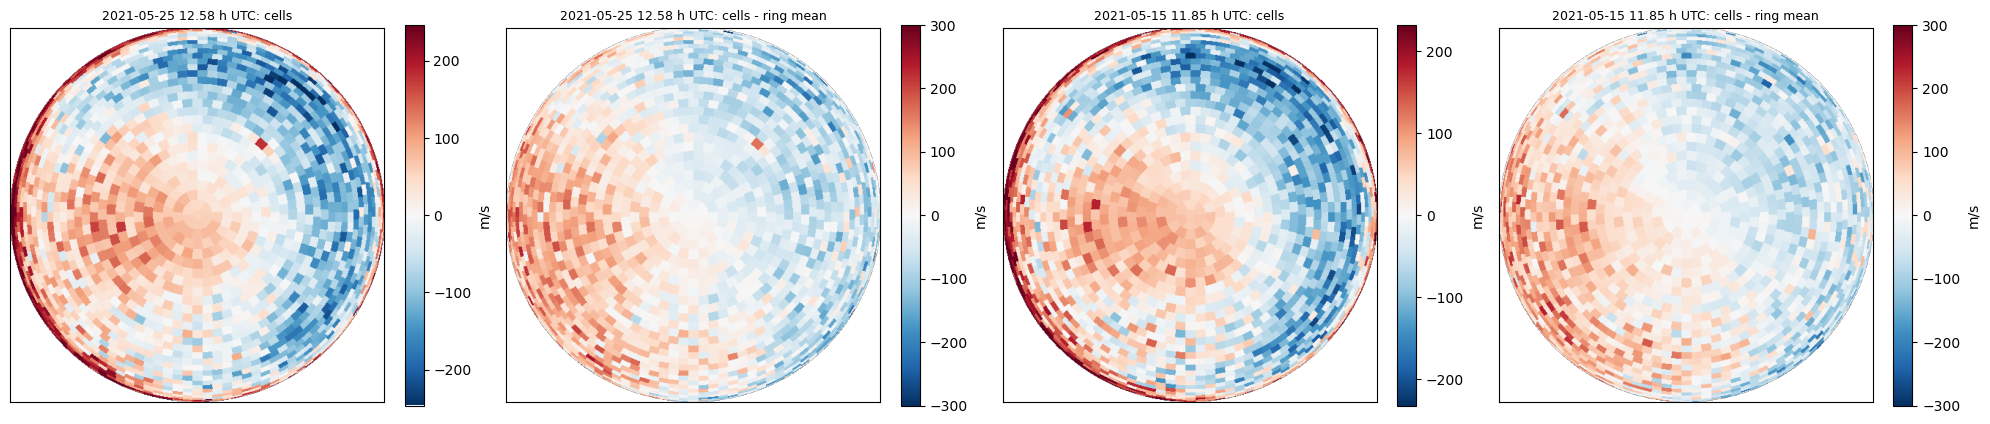

In [7]:
SIZE = 512
cells, npix = sdo.cell_projection((SIZE, SIZE), N_RINGS)
x_pix = (np.tile(np.arange(SIZE), SIZE) + 0.5) / SIZE * 2 - 1                # west > 0, solar radii
x_cell = np.bincount(cells[cells >= 0], weights=x_pix[cells >= 0], minlength=len(npix)) / np.maximum(npix, 1)
ring = sg.ring_of_cells(N_RINGS)

def cell_image(v):
    img = np.full(SIZE * SIZE, np.nan)
    img[cells >= 0] = v[cells[cells >= 0]]
    return img.reshape(SIZE, SIZE)

def rotation_left(v, w):
    """Fit of v = A x + one mean per ring over the cells (weights w): A [m/s at the limb]."""
    k = np.isfinite(v) & (w > 0)
    X = np.column_stack([x_cell[k]] + [(ring[k] == i).astype(float) for i in range(N_RINGS)])
    sq = np.sqrt(w[k])
    return np.linalg.lstsq(X * sq[:, None], v[k] * sq, rcond=None)[0][0]

ex['rot_left'] = np.array([rotation_left(v_exp[i], sw_exp[i]) for i in range(len(ex['jd']))])
fig, axes = plt.subplots(1, 2 * len(DAYS), figsize=(5 * 2 * len(DAYS), 4.4))
for k, d in enumerate(DAYS):
    i = np.flatnonzero(ex['day'] == d)[np.sum(ex['day'] == d) // 2]
    mean_ring = np.array([np.nansum(v_fill[i][ring == r] * sw_exp[i][ring == r]) / np.sum(sw_exp[i][ring == r]) for r in range(N_RINGS)])
    for ax, img, t, lim in ((axes[2 * k], cell_image(v_fill[i]), 'cells', None),
                            (axes[2 * k + 1], cell_image(v_fill[i] - mean_ring[ring]), 'cells - ring mean', 300)):
        lim = lim or np.nanpercentile(np.abs(img), 99)
        im = ax.imshow(img, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim)
        ax.set_title('%s %.2f h UTC: %s' % (d, (ex['jd'][i] + 0.5) % 1 * 24, t), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, label='m/s')
plt.tight_layout()

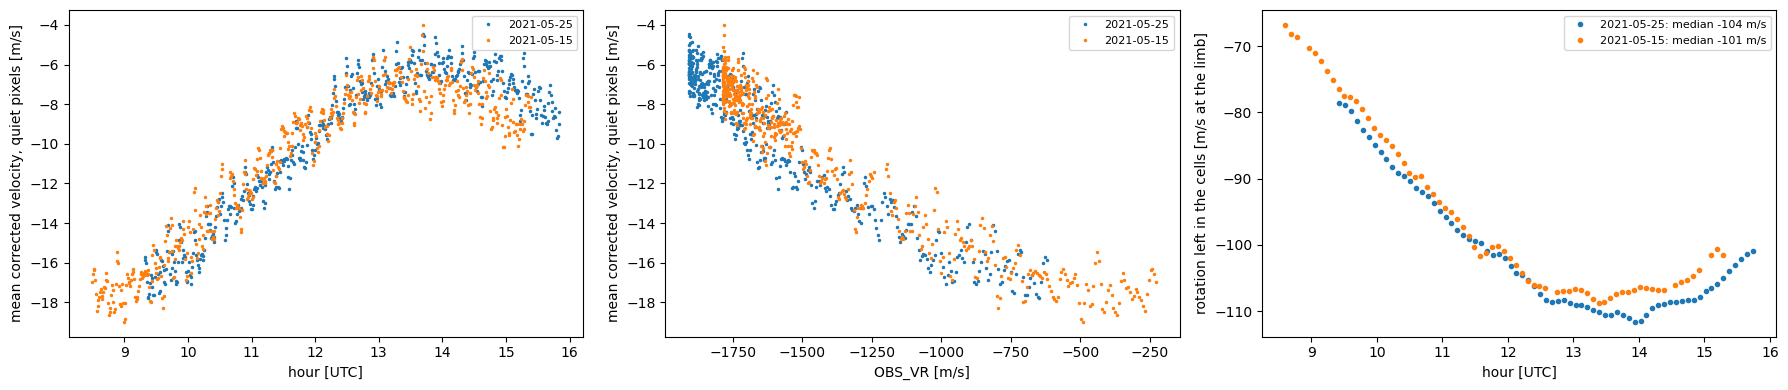

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for d in DAYS:
    h = (fr[fr['day'] == d]['jd'] + 0.5) % 1 * 24
    axes[0].plot(h, fr[fr['day'] == d]['v_quiet_mean'], '.', ms=3, label=d)
    axes[1].plot(fr[fr['day'] == d]['obs_vr'], fr[fr['day'] == d]['v_quiet_mean'], '.', ms=3, label=d)
    m = ex['day'] == d
    axes[2].plot((ex['jd'][m] + 0.5) % 1 * 24, ex['rot_left'][m], 'o', ms=3, label='%s: median %.0f m/s' % (d, np.median(ex['rot_left'][m])))
axes[0].set_xlabel('hour [UTC]'); axes[0].set_ylabel('mean corrected velocity, quiet pixels [m/s]')
axes[1].set_xlabel('OBS_VR [m/s]'); axes[1].set_ylabel('mean corrected velocity, quiet pixels [m/s]')
axes[2].set_xlabel('hour [UTC]'); axes[2].set_ylabel('rotation left in the cells [m/s at the limb]')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()

## 4. Simulations and comparison with HARPS-N

In [9]:
a = Namespace(out=OUT, start=START, conf=os.path.join('..', 'conf', 'starsim_sun_sdo_mps_highres.conf'),
              mps_folder=str(local_path('muram_spectra')), mask=str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'),
              interventions=str(local_path('harpsn_interventions')), n_rings=N_RINGS, window=WINDOW, min_fill=0.8,
              min_exp=5, harpsn=HARPSN, min_obs_quality=MIN_OBS_QUALITY, min_day_exp=MIN_DAY_EXP, results=RESULTS,
              figures=True)
sgh.run_collect(a)

12:39:31 quality: 7 of 142 exposures left out (data_quality != 1: 0, not in the release: 0, obs_quality < 0.99: 7)
12:39:31 days with fewer than 50 exposures left: 0 (0 exposures)
12:39:31 dopplergrams: 1068 frames, window 720 s: 132 of 135 exposures with >= 80 % of the frames (left out: 3)
12:39:31 cells without quiet pixels (ring mean): 134.5 per exposure
12:39:31 132 exposures on 2 days, 66 epochs
12:39:33 2 simulations of 132 exposures: 2 s
   quantity               model  days  exposures  median r  days with r > 0 [%]  median slope  RMS obs (intra-day)  RMS obs - sim (intra-day)
0        rv                maps     2        132     0.415                100.0         8.637                0.575                      0.561
1        rv  maps + dopplergram     2        132     0.185                 50.0         0.057                0.575                      3.570
2      fwhm                maps     2        132     0.208                 50.0        11.076                1.273           

0

In [10]:
new = pd.read_csv(os.path.join(OUT, RESULTS, 'exposures.csv'))
old = pd.read_csv(os.path.join(OLD, OLD_RESULTS, 'exposures.csv'))
new, old = new[new['day'].isin(list(DAYS))], old[old['day'].isin(list(DAYS))]
key = lambda df: np.round(df['jd_utc'] * 86400).astype(np.int64)
both = new.assign(k=key(new)).merge(old.add_suffix('_old').assign(k=key(old)), on='k')
print('exposures: new %d, old %d, both %d' % (len(new), len(old), len(both)))
SERIES = (('%s_obs', 'HARPS-N (rv_raw - JPL)', COL['harpsn'], ''), ('%s_obs', 'HARPS-N (release)', '#888888', '_old'),
          ('%s_maps', 'maps', COL['maps'], ''), ('%s_maps_dopplergram', 'maps + dopplergram (Haywood)', COL['new'], ''),
          ('%s_maps_dopplergram', 'maps + dopplergram (old)', COL['old'], '_old'),
          ('%s_maps_dopplergram_p_modes', 'maps + dopplergram + p modes (old)', COL['old_pm'], '_old'))
LABEL = {'rv': ('RV', 'm/s'), 'fwhm': ('FWHM', 'm/s'), 'bis': ('BIS', 'm/s'), 'contrast': ('contrast', 'ppm')}

def intra(df, col):
    return df[col] - df.groupby('day')[col].transform('median')

rows = []
for q in LABEL:
    for d in DAYS:
        b = both[both['day'] == d]
        for obs_col, obs_name in (('%s_obs' % q, 'rv_raw - JPL'), ('%s_obs_old' % q, 'release')):
            o = intra(b, obs_col)
            for col, name, _, suf in SERIES[2:]:
                s = intra(b, (col % q) + suf)
                rows.append({'quantity': q, 'day': d, 'HARPS-N': obs_name, 'model': name, 'n': len(b),
                             'RMS obs': np.std(o), 'RMS obs - sim': np.std(o - s), 'r': np.corrcoef(o, s)[0, 1]})
stats = pd.DataFrame(rows)
stats.pivot_table(index=['quantity', 'day', 'HARPS-N'], columns='model', values=['RMS obs - sim', 'r'], sort=False).round(2)

exposures: new 132, old 135, both 132


RMS obs - sim                               \
model                                     maps maps + dopplergram (Haywood)   
quantity day        HARPS-N                                                   
rv       2021-05-25 rv_raw - JPL          0.68                         2.87   
                    release               0.77                         2.77   
         2021-05-15 rv_raw - JPL          0.36                         3.74   
                    release               0.35                         3.63   
fwhm     2021-05-25 rv_raw - JPL          1.35                         3.62   
                    release               1.35                         3.62   
         2021-05-15 rv_raw - JPL          1.16                         4.94   
                    release               1.16                         4.94   
bis      2021-05-25 rv_raw - JPL          0.62                         0.85   
                    release               0.62                         0.85   
         2021-05-15 rv_raw - JPL          0.60                         0.91   
                    release               0.60                         0.91   
contrast 2021-05-25 rv_raw - JPL        139.46                       564.92   
                    release             139.42                       564.90   
         2021-05-15 rv_raw - JPL        131.47                       812.21   
                    release             131.44                       812.19   

                                                           \
model                            maps + dopplergram (old)   
quantity day        HARPS-N                                 
rv       2021-05-25 rv_raw - JPL                     0.59   
                    release                          0.50   
         2021-05-15 rv_raw - JPL                     1.08   
                    release                          0.99   
fwhm     2021-05-25 rv_raw - JPL                     1.35   
                    release                          1.35   
         2021-05-15 rv_raw - JPL                     1.12   
                    release                          1.12   
bis      2021-05-25 rv_raw - JPL                     0.94   
                    release                          0.94   
         2021-05-15 rv_raw - JPL                     1.08   
                    release                          1.08   
contrast 2021-05-25 rv_raw - JPL                   142.28   
                    release                        142.25   
         2021-05-15 rv_raw - JPL                   130.08   
                    release                        130.06   

                                                                        r  \
model                            maps + dopplergram + p modes (old)  maps   
quantity day        HARPS-N                                                 
rv       2021-05-25 rv_raw - JPL                               0.59  0.63   
                    release                                    0.51  0.67   
         2021-05-15 rv_raw - JPL                               1.14  0.21   
                    release                                    1.05  0.01   
fwhm     2021-05-25 rv_raw - JPL                               1.33 -0.03   
                    release                                    1.33 -0.03   
         2021-05-15 rv_raw - JPL                               1.13  0.45   
                    release                                    1.13  0.45   
bis      2021-05-25 rv_raw - JPL                               0.95 -0.04   
                    release                                    0.95 -0.04   
         2021-05-15 rv_raw - JPL                               1.08  0.39   
                    release                                    1.08  0.39   
contrast 2021-05-25 rv_raw - JPL                             138.98  0.11   
                    release                                  138.95  0.11   
         2021-05-15 rv_raw - JPL                             1

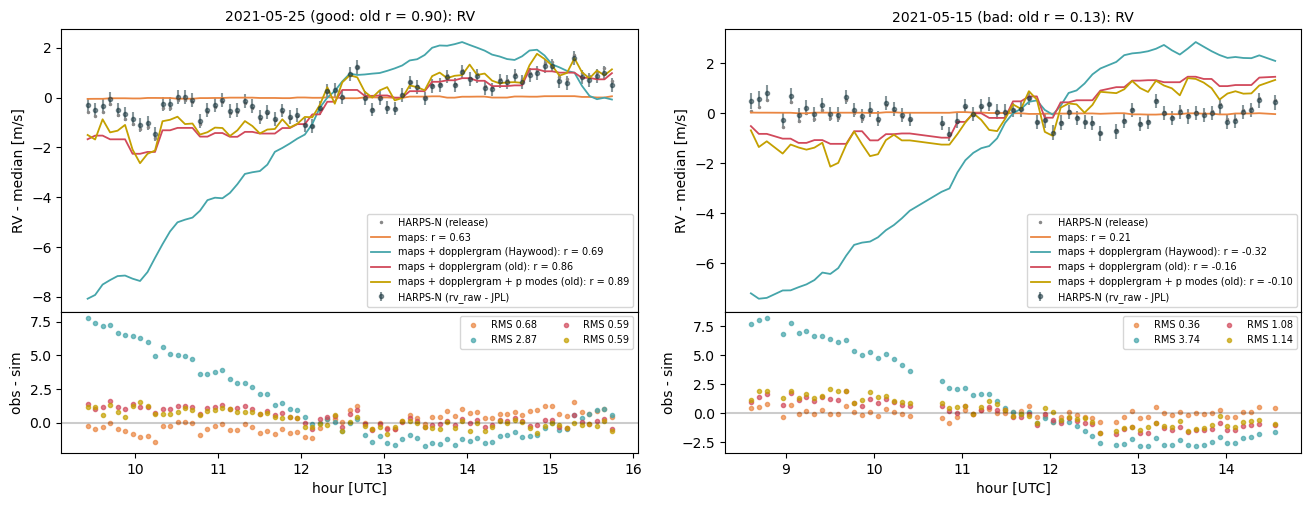

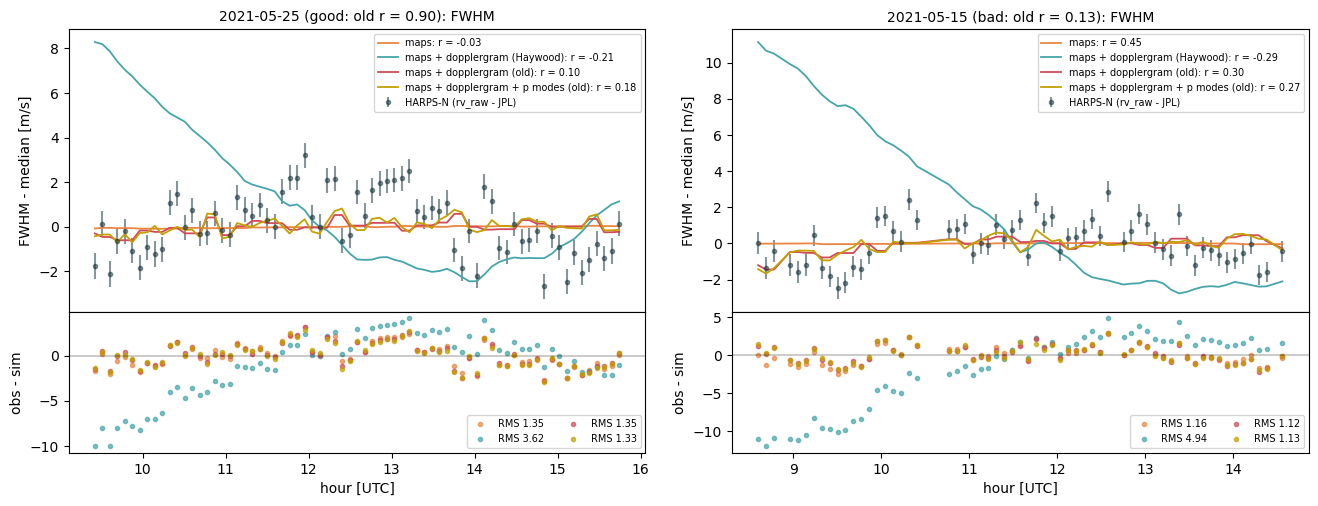

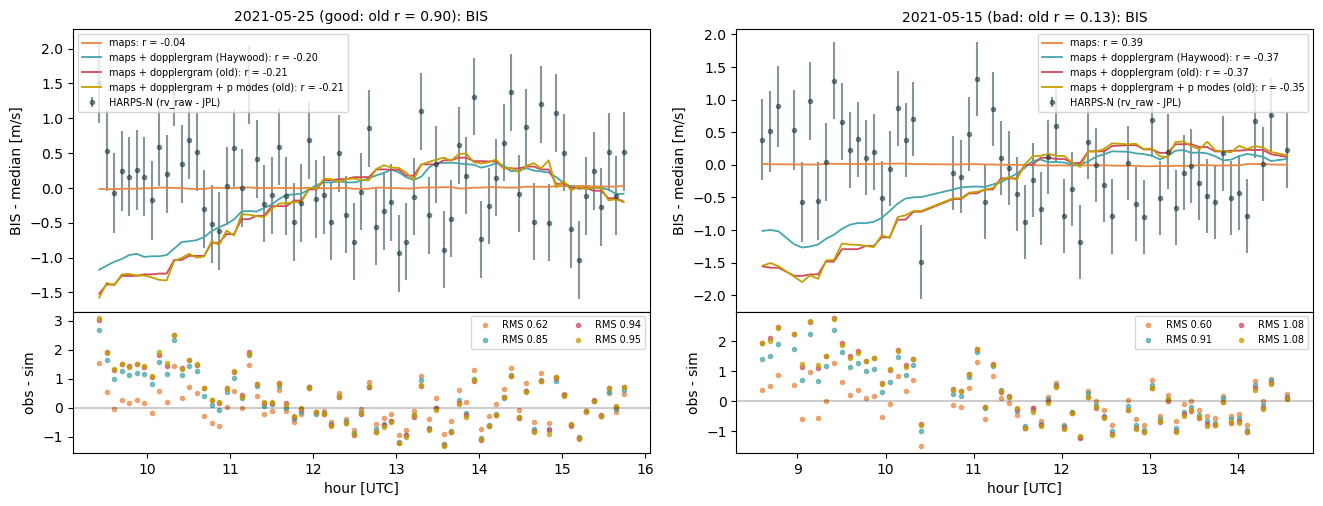

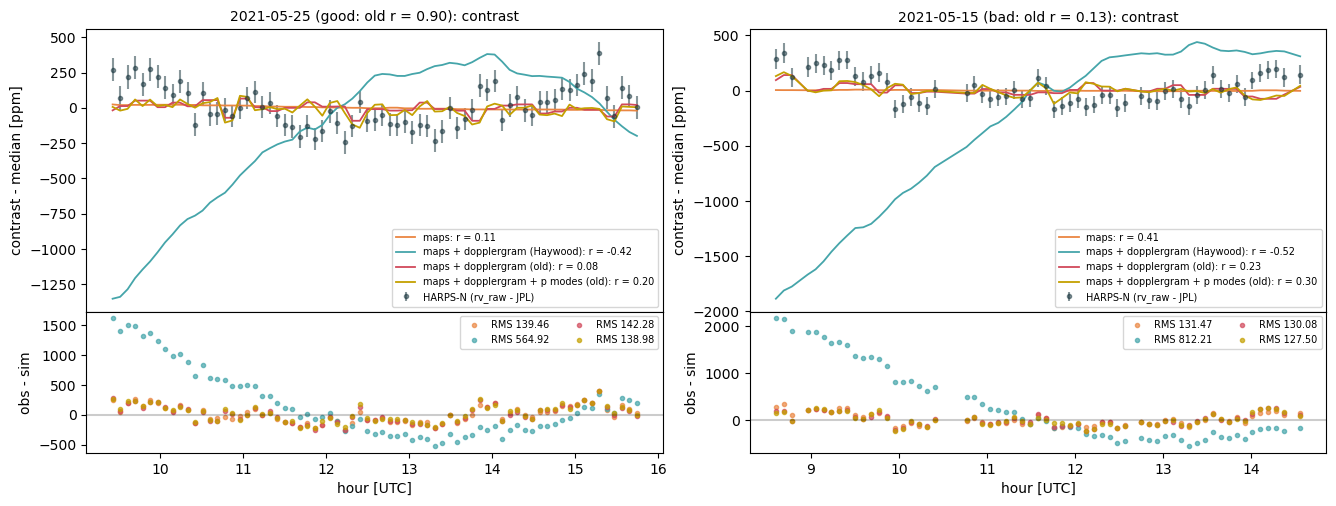

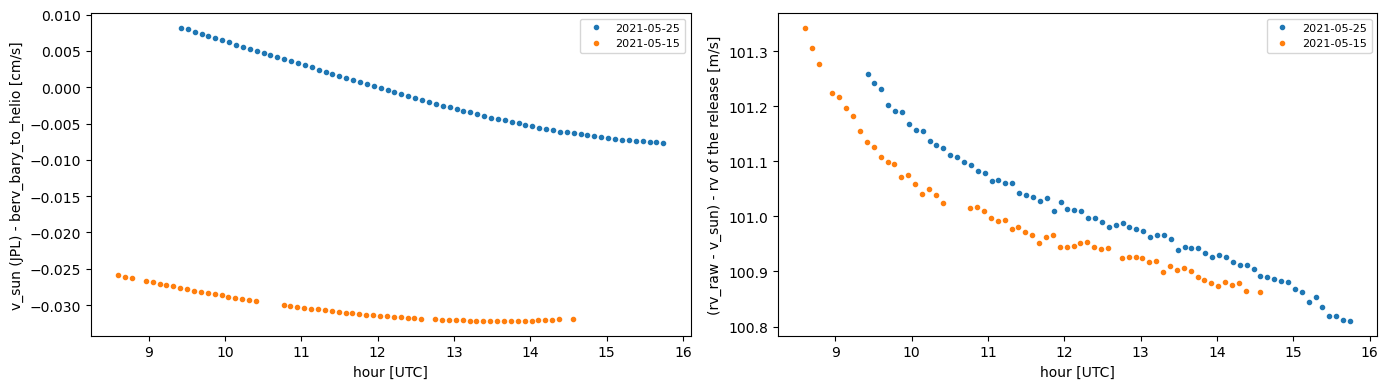

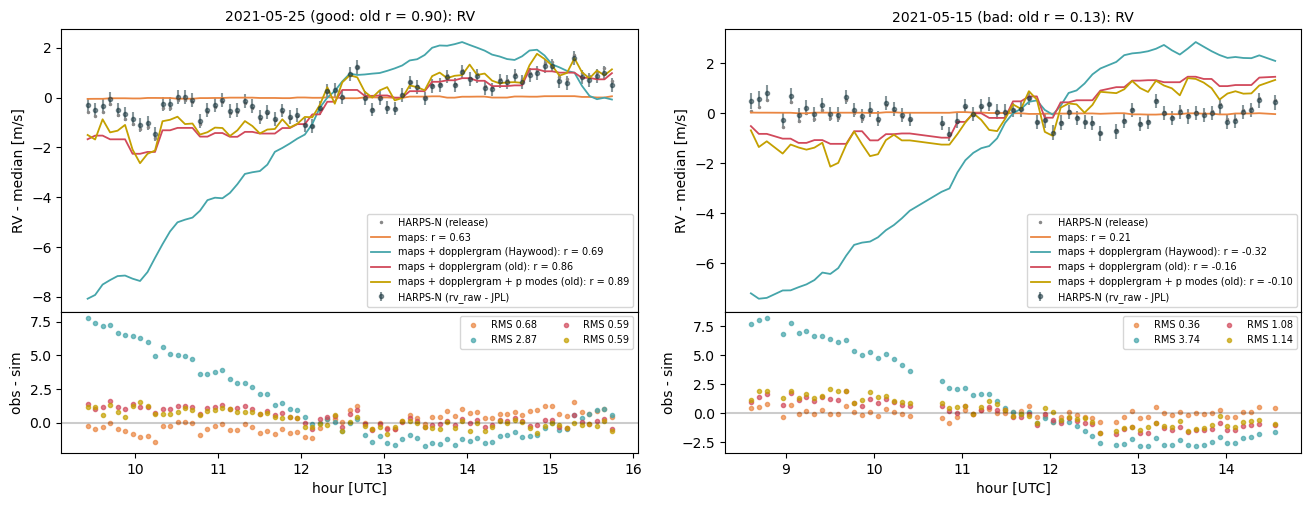

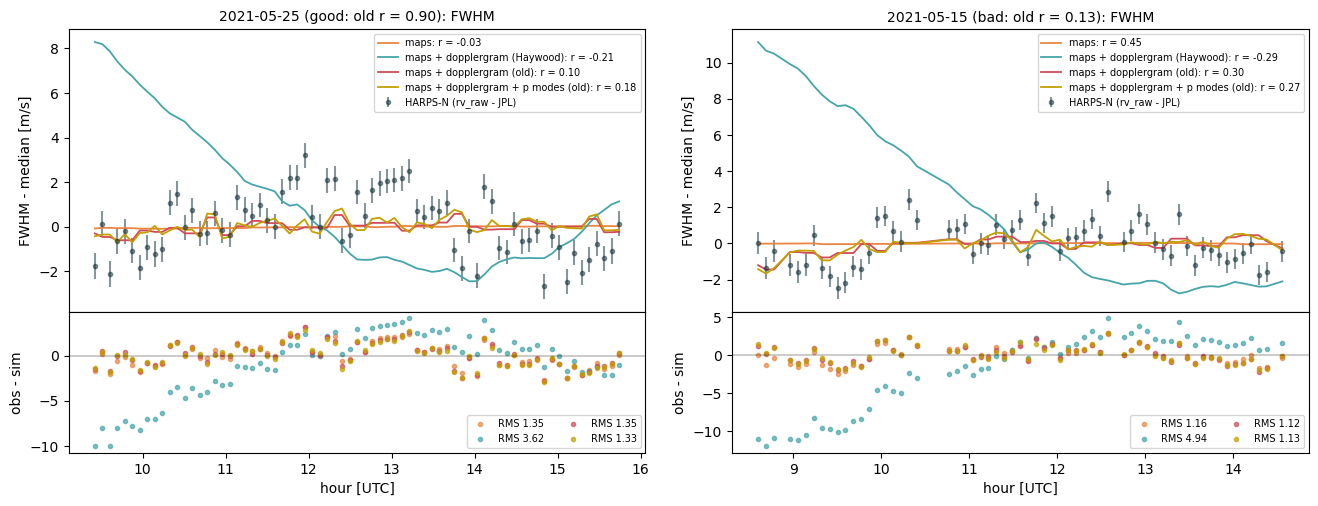

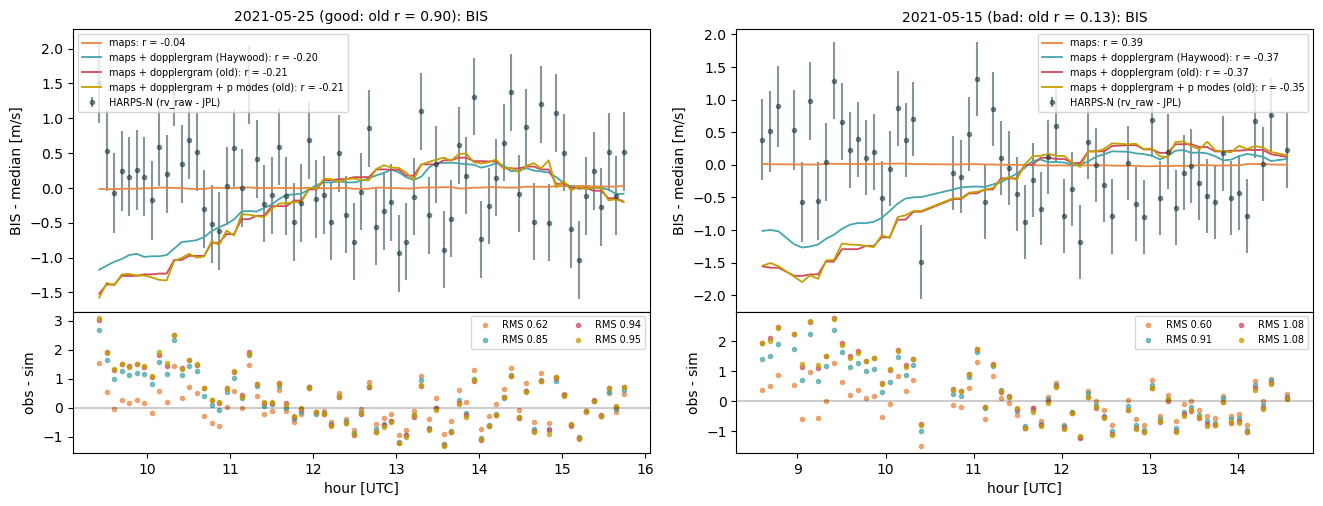

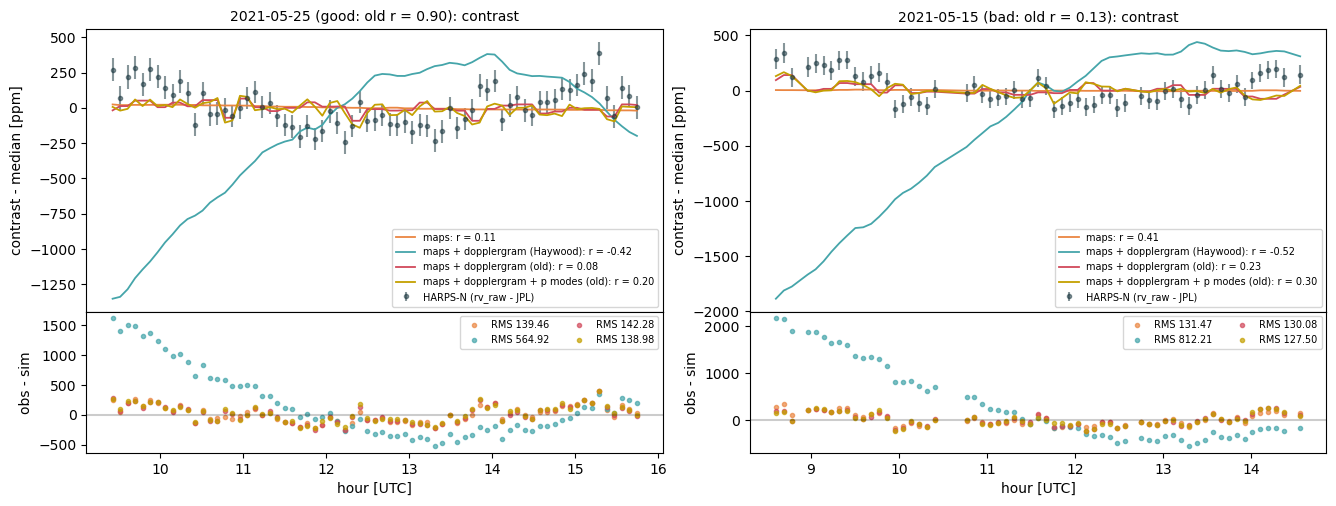

In [14]:
for q, (label, unit) in LABEL.items():
    fig = plt.figure(figsize=(8 * len(DAYS), 5.5))
    outer = fig.add_gridspec(1, len(DAYS), wspace=0.15)
    for k, d in enumerate(DAYS):
        inner = outer[k].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
        ax, ar = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        b = both[both['day'] == d]
        h = (b['jd_utc'] + 0.5) % 1 * 24
        o = intra(b, '%s_obs' % q)
        ax.errorbar(h, o, yerr=b['%s_err' % q], fmt='o', ms=3, color=COL['harpsn'], alpha=0.5, label='HARPS-N (rv_raw - JPL)')
        if q == 'rv':
            ax.plot(h, intra(b, 'rv_obs_old'), '.', ms=3, color='#888888', label='HARPS-N (release)')
        for col, name, c, suf in SERIES[2:]:
            s = intra(b, (col % q) + suf)
            ax.plot(h, s, '-', color=c, lw=1.3, label='%s: r = %.2f' % (name, np.corrcoef(o, s)[0, 1]))
            ar.plot(h, o - s, 'o', ms=3, color=c, alpha=0.7, label='RMS %.2f' % np.std(o - s))
        ar.axhline(0, color='k', alpha=0.2)
        ax.tick_params(labelbottom=False)
        ax.set_title('%s (%s): %s' % (d, DAYS[d], label), fontsize=10)
        ax.set_ylabel('%s - median [%s]' % (label, unit)); ar.set_ylabel('obs - sim'); ar.set_xlabel('hour [UTC]')
        ax.legend(fontsize=7); ar.legend(fontsize=7, ncols=2)
    plt.show()

## 5. HARPS-N in the rest frame of the Sun

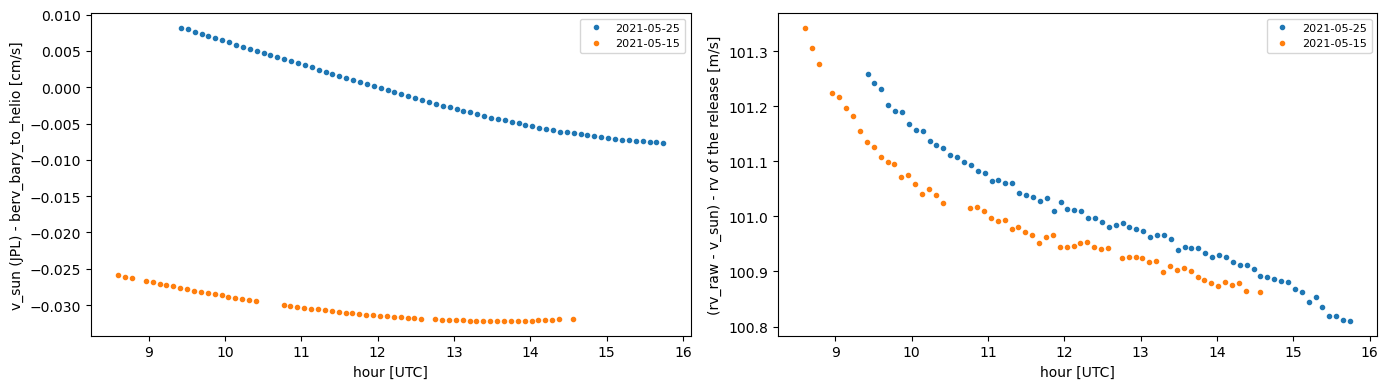

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for d in DAYS:
    b = new[new['day'] == d]
    h = (b['jd_utc'] + 0.5) % 1 * 24
    axes[0].plot(h, 100 * (b['v_sun_jpl'] - b['berv_bary_to_helio']), '.', label=d)
    axes[1].plot(h, b['rv_obs'] - b['rv_release'], '.', label=d)
axes[0].set_ylabel('v_sun (JPL) - berv_bary_to_helio [cm/s]')
axes[1].set_ylabel('(rv_raw - v_sun) - rv of the release [m/s]')
for ax in axes:
    ax.set_xlabel('hour [UTC]'); ax.legend(fontsize=8)
plt.tight_layout()